# Chromosome 7 heatmaps: K562

Compare observed and predicted Hi-C maps for three regions in H1hESC and K562.
Run all cells to recompute the six predictions and display the result below.

**Requirements:** Python 3.9+, PyTorch 2.0+, NumPy, SciPy, Matplotlib, and IPython.
All model code is included; no external model package or compiled Mamba extension
is required.


## Imports

In [1]:
from pathlib import Path
from io import BytesIO
import math
import os
import pickle
import warnings

import numpy as np
from scipy.ndimage import gaussian_filter
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import Image, display

torch.set_num_threads(4)
plt.ioff();


## Data, checkpoints, and regions

Environment variables can override the configured locations. Each cell-type data folder must contain the three regional PKL files with `sequence_one_hot`, `omics_signals`, and `hic_matrix` arrays. Set `MAMBAHIC_DEVICE=cpu` to run on CPU, or select a CUDA device such as `cuda:0`.

In [2]:
cwd = Path.cwd().resolve()
PROJECT_ROOT = next((parent for parent in [cwd, *cwd.parents]
                     if (parent / "weights").is_dir() and (parent / "notebooks").is_dir()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Cannot find the repository's weights and notebooks directories.")

DATA_ROOT = Path(os.environ.get(
    "MAMBAHIC_DATA_ROOT", str(PROJECT_ROOT / "data" / "chr7")
))
WEIGHTS_ROOT = Path(os.environ.get(
    "MAMBAHIC_WEIGHTS_ROOT", str(PROJECT_ROOT)
))
DEVICE = torch.device(os.environ.get(
    "MAMBAHIC_DEVICE", "cuda" if torch.cuda.is_available() else "cpu"
))

REGIONS = [
    ("chr7", 106_176_000, 107_200_000),
    ("chr7", 71_232_000, 72_256_000),
    ("chr7", 147_776_000, 148_800_000),
]
CELL_TYPES = ("H1hESC", "K562")

CHECKPOINTS = {
    "K562": WEIGHTS_ROOT / "weights/runs_yf/K562_ex7_22/best_model.pth",
}
MODEL_BY_ROW = {
    "H1hESC": ["K562"] * len(REGIONS),
    "K562": ["K562"] * len(REGIONS),
}
FIGURE_TITLE = "K562 chr7: observed and predicted Hi-C"


## Pure PyTorch Mamba

In [3]:
from __future__ import annotations

class Mamba(nn.Module):
    """Pure PyTorch compatibility implementation of mamba_ssm.Mamba.

    This matches the Mamba v1 parameter names used by the saved checkpoint.
    It is intended for CPU inference when the CUDA extension is unavailable.
    """

    def __init__(
        self,
        d_model: int,
        d_state: int = 16,
        d_conv: int = 4,
        expand: int = 2,
        dt_rank: int | str = "auto",
        dt_min: float = 0.001,
        dt_max: float = 0.1,
        dt_init: str = "random",
        dt_scale: float = 1.0,
        dt_init_floor: float = 1e-4,
        conv_bias: bool = True,
        bias: bool = False,
        use_fast_path: bool = True,
        layer_idx=None,
        device=None,
        dtype=None,
        **kwargs,
    ):
        super().__init__()
        factory_kwargs = {"device": device, "dtype": dtype}
        self.d_model = d_model
        self.d_state = d_state
        self.d_conv = d_conv
        self.expand = expand
        self.d_inner = int(self.expand * self.d_model)
        self.dt_rank = math.ceil(self.d_model / 16) if dt_rank == "auto" else int(dt_rank)

        self.in_proj = nn.Linear(self.d_model, self.d_inner * 2, bias=bias, **factory_kwargs)
        self.conv1d = nn.Conv1d(
            in_channels=self.d_inner,
            out_channels=self.d_inner,
            bias=conv_bias,
            kernel_size=d_conv,
            groups=self.d_inner,
            padding=d_conv - 1,
            **factory_kwargs,
        )
        self.activation = "silu"
        self.act = nn.SiLU()

        self.x_proj = nn.Linear(self.d_inner, self.dt_rank + self.d_state * 2, bias=False, **factory_kwargs)
        self.dt_proj = nn.Linear(self.dt_rank, self.d_inner, bias=True, **factory_kwargs)

        dt_init_std = self.dt_rank**-0.5 * dt_scale
        if dt_init == "constant":
            nn.init.constant_(self.dt_proj.weight, dt_init_std)
        elif dt_init == "random":
            nn.init.uniform_(self.dt_proj.weight, -dt_init_std, dt_init_std)
        else:
            raise NotImplementedError

        dt = torch.exp(
            torch.rand(self.d_inner, **factory_kwargs) * (math.log(dt_max) - math.log(dt_min))
            + math.log(dt_min)
        ).clamp(min=dt_init_floor)
        inv_dt = dt + torch.log(-torch.expm1(-dt))
        with torch.no_grad():
            self.dt_proj.bias.copy_(inv_dt)
        self.dt_proj.bias._no_reinit = True

        A = torch.arange(1, self.d_state + 1, dtype=torch.float32, device=device).repeat(self.d_inner, 1)
        self.A_log = nn.Parameter(torch.log(A))
        self.A_log._no_weight_decay = True
        self.D = nn.Parameter(torch.ones(self.d_inner, device=device))
        self.D._no_weight_decay = True
        self.out_proj = nn.Linear(self.d_inner, self.d_model, bias=bias, **factory_kwargs)

    def forward(self, hidden_states, inference_params=None):
        batch, seqlen, _ = hidden_states.shape

        xz = self.in_proj(hidden_states).transpose(1, 2)
        x, z = xz.chunk(2, dim=1)
        x = self.act(self.conv1d(x)[..., :seqlen])

        x_dbl = self.x_proj(x.transpose(1, 2).reshape(batch * seqlen, self.d_inner))
        dt, B, C = torch.split(x_dbl, [self.dt_rank, self.d_state, self.d_state], dim=-1)
        dt = self.dt_proj.weight @ dt.t()
        dt = dt.reshape(self.d_inner, batch, seqlen).permute(1, 0, 2).contiguous()
        B = B.reshape(batch, seqlen, self.d_state).transpose(1, 2).contiguous()
        C = C.reshape(batch, seqlen, self.d_state).transpose(1, 2).contiguous()

        y = self._selective_scan(x, dt, B, C, z)
        return self.out_proj(y.transpose(1, 2))

    def _selective_scan(self, u, delta, B, C, z):
        dtype_in = u.dtype
        u_f = u.float()
        delta_f = F.softplus(delta.float() + self.dt_proj.bias.float().view(1, -1, 1))
        A = -torch.exp(self.A_log.float())
        B_f = B.float()
        C_f = C.float()

        state = torch.zeros(u.shape[0], self.d_inner, self.d_state, device=u.device, dtype=torch.float32)
        ys = []
        for i in range(u.shape[-1]):
            delta_i = delta_f[:, :, i]
            deltaA = torch.exp(delta_i.unsqueeze(-1) * A.unsqueeze(0))
            deltaB_u = delta_i.unsqueeze(-1) * B_f[:, :, i].unsqueeze(1) * u_f[:, :, i].unsqueeze(-1)
            state = state * deltaA + deltaB_u
            y_i = torch.sum(state * C_f[:, :, i].unsqueeze(1), dim=-1)
            ys.append(y_i)

        y = torch.stack(ys, dim=-1)
        y = y + u_f * self.D.float().view(1, -1, 1)
        y = y * F.silu(z.float())
        return y.to(dtype=dtype_in)

## CNN-Mamba model

In [4]:
class DownsampleBlock(nn.Module):
    def __init__(self, in_channels: int, out_channels: int, kernel_size: int, stride: int, activation: str = "relu"):
        super().__init__()
        act = nn.GELU() if activation == "gelu" else nn.ReLU(inplace=True)
        self.block = nn.Sequential(
            nn.Conv1d(in_channels, out_channels, kernel_size, stride=stride, padding=kernel_size // 2),
            nn.BatchNorm1d(out_channels),
            act,
        )

    def forward(self, x):
        return self.block(x)


class DeepFeatureResBlock(nn.Module):
    def __init__(self, channels: int, kernel_size: int = 7):
        super().__init__()
        padding = (kernel_size - 1) // 2
        self.block = nn.Sequential(
            nn.Conv1d(channels, channels, kernel_size, stride=1, padding=padding),
            nn.BatchNorm1d(channels),
            nn.GELU(),
            nn.Conv1d(channels, channels, kernel_size, stride=1, padding=padding),
            nn.BatchNorm1d(channels),
        )
        self.activation = nn.GELU()

    def forward(self, x):
        return self.activation(x + self.block(x))


class HybridCNNMambaEncoder(nn.Module):
    def __init__(self, in_channels: int, d_model: int = 128, num_cnn_blocks: int = 3, num_mamba_layers: int = 3, is_sequence: bool = True):
        super().__init__()
        self.is_sequence = is_sequence
        self.use_bidirectional_wrapper = True
        if self.is_sequence:
            self.downsampler = nn.Sequential(
                DownsampleBlock(in_channels, 48, kernel_size=5, stride=5, activation="gelu"),
                DownsampleBlock(48, 96, kernel_size=5, stride=5, activation="gelu"),
                DownsampleBlock(96, d_model, kernel_size=5, stride=5, activation="gelu"),
                DownsampleBlock(d_model, d_model, kernel_size=5, stride=4, activation="gelu"),
                DownsampleBlock(d_model, d_model, kernel_size=5, stride=4, activation="gelu"),
            )
        else:
            self.downsampler = nn.Sequential(nn.Conv1d(in_channels, d_model, kernel_size=1), nn.GELU())
        self.cnn_feature_extractor = nn.Sequential(*[DeepFeatureResBlock(d_model) for _ in range(num_cnn_blocks)])
        self.mamba_layers = nn.ModuleList([Mamba(d_model=d_model, d_state=16, d_conv=4, expand=2) for _ in range(num_mamba_layers)])
        self.norm = nn.LayerNorm(d_model)

    def forward(self, x):
        x = self.downsampler(x)
        x = self.cnn_feature_extractor(x).transpose(1, 2)
        x = self.norm(x)
        if not self.use_bidirectional_wrapper:
            for layer in self.mamba_layers:
                x = x + layer(x)
            return x.transpose(1, 2)
        for mamba_layer in self.mamba_layers:
            x_fw = mamba_layer(x)
            x_bw = torch.flip(mamba_layer(torch.flip(x, dims=[1])), dims=[1])
            x = x + x_fw + x_bw
        return x.transpose(1, 2)


class SimpleFusion(nn.Module):
    def __init__(self, in_channels: int, out_channels: int):
        super().__init__()
        self.fusion_conv = nn.Sequential(
            nn.Conv1d(in_channels * 2, out_channels, kernel_size=1),
            nn.BatchNorm1d(out_channels),
            nn.GELU(),
        )

    def forward(self, seq_emb, omics_emb):
        return self.fusion_conv(torch.cat([seq_emb, omics_emb], dim=1))


class ConvResBlock(nn.Module):
    def __init__(self, channels: int, kernel_size: int = 3):
        super().__init__()
        padding = (kernel_size - 1) // 2
        self.block = nn.Sequential(
            nn.Conv2d(channels, channels, kernel_size, padding=padding),
            nn.BatchNorm2d(channels),
            nn.GELU(),
            nn.Conv2d(channels, channels, kernel_size, padding=padding),
            nn.BatchNorm2d(channels),
        )
        self.activation = nn.GELU()

    def forward(self, x):
        return self.activation(x + self.block(x))


class PracticalOuterProductDecoder(nn.Module):
    def __init__(self, in_channels: int = 128, bottleneck_channels: int = 16, num_blocks: int = 4):
        super().__init__()
        self.bottleneck = nn.Conv1d(in_channels, bottleneck_channels, 1)
        self.initial_conv = nn.Conv2d(bottleneck_channels * 2, 64, 1)
        self.res_blocks = nn.Sequential(*[ConvResBlock(64) for _ in range(num_blocks)])
        self.final_conv = nn.Conv2d(64, 1, 3, padding=1)

    def forward(self, fused_embedding):
        _, _, length = fused_embedding.shape
        bottleneck_emb = self.bottleneck(fused_embedding)
        x1 = bottleneck_emb.unsqueeze(3).expand(-1, -1, length, length)
        x2 = bottleneck_emb.unsqueeze(2).expand(-1, -1, length, length)
        x = self.initial_conv(torch.cat([x1, x2], dim=1))
        x = self.final_conv(self.res_blocks(x))
        return (x + x.transpose(-2, -1)) / 2


class CNNMambaHybridModelLegacy(nn.Module):
    """Original GM12878 Figure 04 model matching output_GM12878_train_64stride/best_model.pth."""

    def __init__(
        self,
        seq_in_channels: int = 4,
        num_omics_features: int = 4,
        d_model: int = 128,
        fusion_out_dim: int = 128,
        num_cnn_blocks: int = 3,
        num_mamba_layers: int = 3,
        decoder_bottleneck_channels: int = 48,
        decoder_num_blocks: int = 6,
    ):
        super().__init__()
        self.seq_encoder = HybridCNNMambaEncoder(seq_in_channels, d_model, num_cnn_blocks, num_mamba_layers, is_sequence=True)
        self.omics_encoder = HybridCNNMambaEncoder(num_omics_features, d_model, num_cnn_blocks, num_mamba_layers, is_sequence=False)
        self.fusion_module = SimpleFusion(in_channels=d_model, out_channels=fusion_out_dim)
        self.decoder = PracticalOuterProductDecoder(fusion_out_dim, decoder_bottleneck_channels, decoder_num_blocks)

    def encode_fused(self, seq, omics):
        seq_emb = self.seq_encoder(seq)
        omics_emb = self.omics_encoder(omics)
        return self.fusion_module(seq_emb, omics_emb)

    def forward(self, seq, omics):
        return self.decoder(self.encode_fused(seq, omics)).squeeze(1)

## Load inputs and checkpoints

In [5]:
def load_model(checkpoint):
    with warnings.catch_warnings():
        warnings.filterwarnings("ignore", message="TypedStorage is deprecated.*")
        state = torch.load(checkpoint, map_location="cpu", weights_only=True)
    if "model_state_dict" in state:
        state = state["model_state_dict"]
    elif "state_dict" in state:
        state = state["state_dict"]
    state = {key.removeprefix("module."): value for key, value in state.items()}
    model = CNNMambaHybridModelLegacy(seq_in_channels=4, num_omics_features=4)
    model.load_state_dict(state, strict=True)
    return model.to(DEVICE).eval()


def load_sample(cell, chromosome, start, end):
    path = DATA_ROOT / cell / f"{chromosome}_{start}_{end}.pkl"
    with path.open("rb") as handle:
        return pickle.load(handle)


def observed_heatmap(raw):
    matrix = np.log2(np.maximum(np.asarray(raw, dtype=np.float64), 0.0) + 1.0)
    np.fill_diagonal(matrix, 0.0)
    return matrix.astype(np.float32)


## Predict the six Hi-C maps

In [6]:
models = {name: load_model(path) for name, path in CHECKPOINTS.items()}
samples = {}
predictions = {}

for row, (chromosome, start, end) in enumerate(REGIONS):
    for cell in CELL_TYPES:
        sample = load_sample(cell, chromosome, start, end)
        samples[(row, cell)] = sample
        sequence = torch.from_numpy(
            sample["sequence_one_hot"].astype(np.float32)
        ).unsqueeze(0).to(DEVICE)
        omics = torch.from_numpy(
            sample["omics_signals"].astype(np.float32)
        ).unsqueeze(0).to(DEVICE)
        model = models[MODEL_BY_ROW[cell][row]]
        with torch.inference_mode(), torch.amp.autocast(
            device_type=DEVICE.type, enabled=DEVICE.type == "cuda"
        ):
            prediction = model(sequence, omics).squeeze(0).float().cpu().numpy()
        assert prediction.shape == (512, 512), "Unexpected prediction shape."
        assert np.isfinite(prediction).all(), "Prediction contains non-finite values."
        predictions[(row, cell)] = prediction


## Result

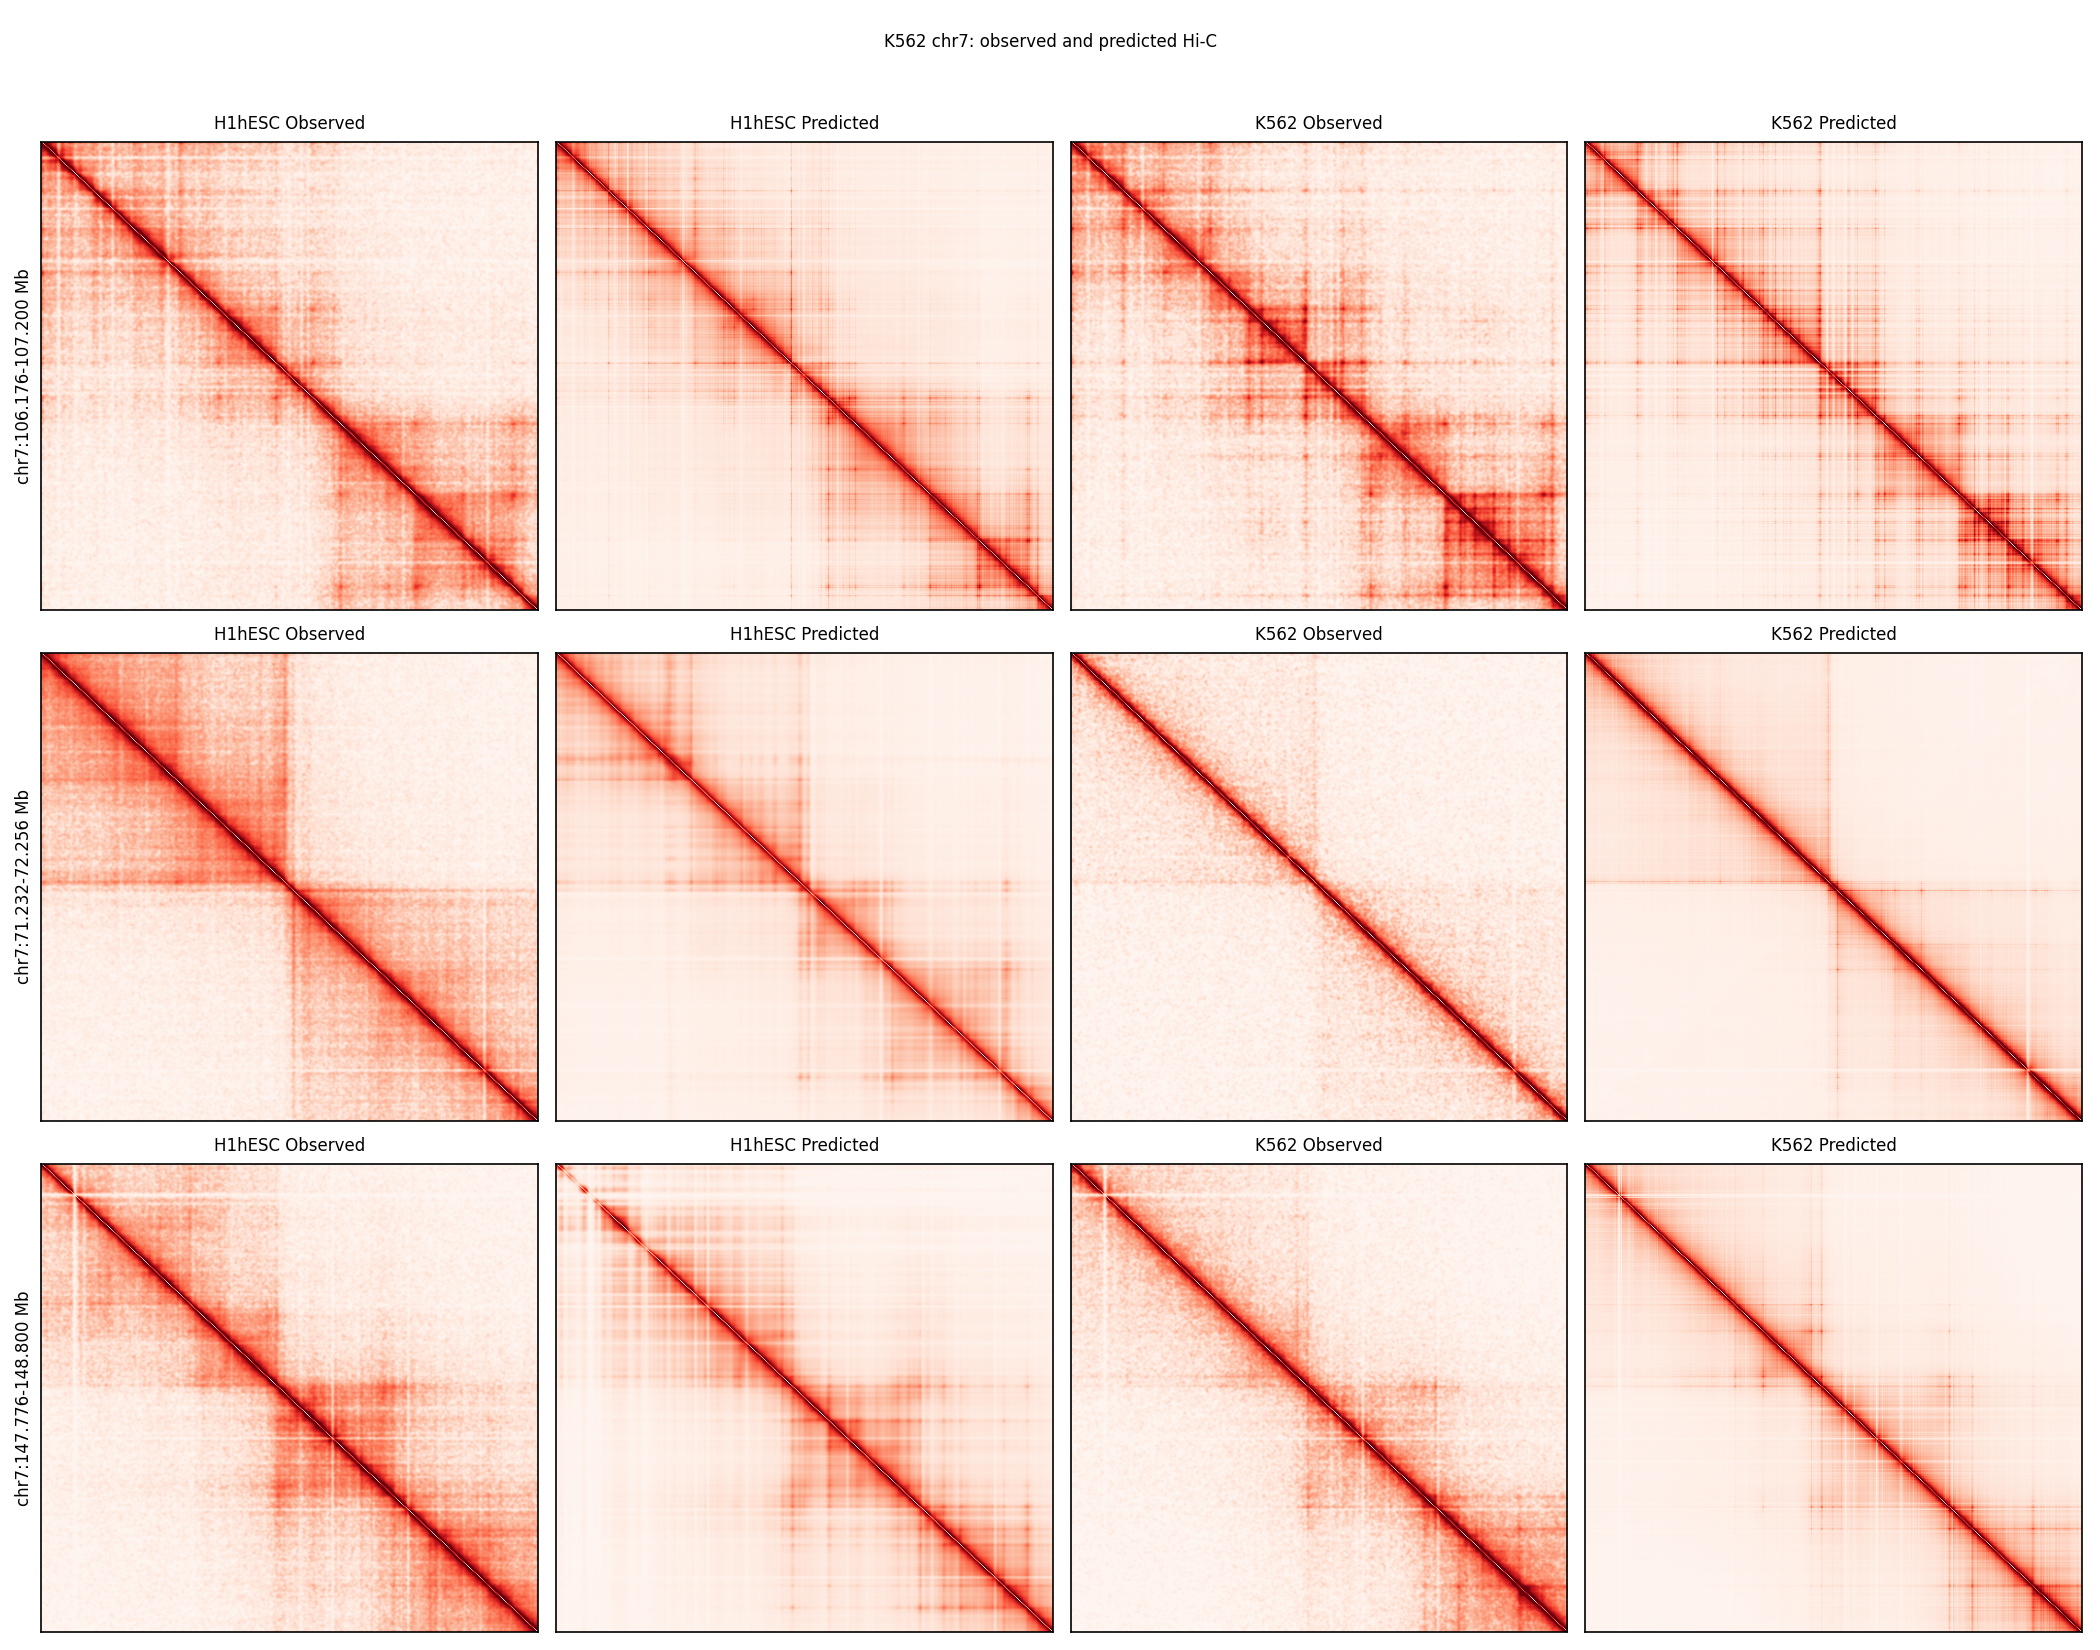

In [7]:
with plt.rc_context({
    "font.family": "DejaVu Sans", "font.size": 8,
    "axes.titlesize": 8, "figure.titlesize": 8,
}):
    figure, axes = plt.subplots(3, 4, figsize=(14, 11))
    for row, (chromosome, start, end) in enumerate(REGIONS):
        for column, cell in enumerate(CELL_TYPES):
            observed = observed_heatmap(samples[(row, cell)]["hic_matrix"])
            positive = observed[observed > 0]
            vmax = float(np.percentile(positive, 99)) if positive.size else 1.0
            for offset, matrix, label in [
                (0, observed, "Observed"),
                (1, predictions[(row, cell)], "Predicted"),
            ]:
                axis = axes[row, column * 2 + offset]
                axis.imshow(matrix, cmap="Reds", vmin=0, vmax=vmax, aspect="auto")
                axis.set_title(f"{cell} {label}")
                axis.set_xticks([])
                axis.set_yticks([])
        axes[row, 0].set_ylabel(
            f"{chromosome}:{start / 1e6:.3f}-{end / 1e6:.3f} Mb", fontsize=8
        )
    figure.suptitle(FIGURE_TITLE, fontsize=8)
    figure.tight_layout(rect=[0, 0, 1, 0.96])
    with BytesIO() as buffer:
        figure.savefig(buffer, format="png", dpi=150)
        display(Image(data=buffer.getvalue()))
    plt.close(figure)
